# Validating the aggregation and the stress components

**Question:** When the engine's test batteries are run on Banco Andino's capital aggregation and on its stress satellites,
which components hold up and which fail, and what does each failure mean for the capital number?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 06 of this topic (the aggregation, the satellites and the capital plan)
- **Reading time:** about 60 minutes

## Objectives

By the end of this notebook you can:

- run the seven aggregation tests of the engine on Banco Andino's capital and read each light and its statistic, with the rule
  that sets it;
- run the Monte Carlo agreement test in the one case where the square-root formula is exact, and plant a horizon mismatch for
  the engine to catch;
- back-cast the five satellites out of time, read why every one of them is red, and watch the engine refuse a fit window that
  leaks into the episode;
- run the sign test, the scenario severity test and the bottom-up rule, and say what each does and does not prove;
- read the whole battery at once and say what it means for the stressed credit loss of the case.

## Setup

Install the pinned notebook environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or install only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds the whole environment, `.venv-notebooks`, for you. A notebook never installs anything by itself. 
The next cell imports what the notebook uses and prints the versions of the packages, so that you can compare them with the pins.

In [1]:
# Imports, versions and the reader of the committed documents (three folders below the repository root)
import importlib.metadata as md
import json
from collections import Counter
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats
from riskvalidation.aggregation import copulas as cop
from riskvalidation.aggregation import simple
from riskvalidation.validation import aggregation as agg_tests
from riskvalidation.validation import portfolio as port_tests
from riskvalidation.validation import stress as stress_tests

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
DERIVED = Path("../../..").resolve() / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

This notebook reads the **test rows** of **C18** (Banco Andino) and the inputs they need.

- **Owner and licence:** the documents are written by this repository's offline pipeline (`data-pipeline/pipeline/cases/c18/`) with the engine `riskvalidation` and committed under `data/derived/C18/`. The scenario paths come from the Federal Reserve (public domain), the EBA and ESRB (reproduction authorised with the source acknowledged) and the NGFS (derived-only: only the few variables the case uses). **Banco Andino is a synthetic bank**: its book and capital are calibrated to public aggregates, and the scenario paths are real United States and euro-area paths transposed onto its jump-off, so the satellites are a US-calibrated adaptation.
- **Truth status:** `synthetic-calibrated`. There is no answer key for the bank; the checks of this notebook are recomputations of committed numbers with the engine, not comparisons with a published result.
- **Baked by:** `riskvalidation` 1.0.1 (seed 42), the version this notebook installs, so a recomputation is expected to match to rounding.
- **Files read:** `data/derived/C18/baseline.json` (the aggregation and the stress test rows, the marginals, the band, the back-cast block, the severity rows), `t-copula-baseline.json` (the correlation-stress band and the two aggregation tests the baseline does not carry), `fed-2026-severely-adverse.json`, `eba-2025-adverse.json` and `ngfs-delayed-transition.json` (the severity of each scenario) and `models-banco-andino.json` (the satellite coefficients). A **test row** is one engine test call stored as a dictionary: `test_id`, `model_id`, `segment`, `statistic`, `metric`, `light` and `extras`.
- **What the lights are.** The aggregation and stress tests are **Contraste internal gates**, stated as such, not regulatory thresholds and not hypothesis tests: each function states its rule in its docstring and records its parameters in `extras["thresholds"]`. The engine states no compliance claim.

In [2]:
# The baseline document and its test rows, the second aggregation document, the scenario variants and the models
baseline_doc = read_json("C18/baseline.json")
baseline = baseline_doc["outputs"]
agg = baseline["aggregation"]
second = read_json("C18/t-copula-baseline.json")
models = read_json("C18/models-banco-andino.json")["fit"]
names = ("eba-2025-adverse", "fed-2026-severely-adverse", "ngfs-delayed-transition")
variants = {name: read_json(f"C18/{name}.json") for name in names}
baked = baseline_doc["provenance"]["riskvalidation_version"]
print("test rows baked by riskvalidation, installed", baked, rv.__version__)
R = np.array(agg["correlation"]["matrix"])
ec = np.array([m["ec_clp_m"] for m in agg["marginals"]])
band = {(r["method"], r["nu"]): r["capital_clp_m"] for r in agg["band"]}
COLOUR = {"green": "#3a8f5c", "amber": "#d9a21b", "red": "#b23a48", "not_evaluated": "#9aa5b1", "error": "#6c757d"}
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated",
         "error": "error"}
TEST = {"aggregation.simple_sum_and_variance_covariance": "simple sum and square-root anchor",
        "aggregation.copula_choice_sensitivity": "copula choice",
        "aggregation.worst_case_bracket": "worst-case bracket",
        "aggregation.correlation_stress": "correlation stress",
        "aggregation.diversification_sign": "diversification sign",
        "aggregation.horizon_confidence_consistency": "horizon and level",
        "portfolio.euler_additivity": "Euler additivity",
        "aggregation.elliptical_mc_agreement": "Monte Carlo agreement",
        "aggregation.rosenberg_schuermann_reference": "published reference",
        "stress.satellite_backcast": "satellite back-cast",
        "stress.sensitivity_monotonicity": "sign of the coefficients",
        "stress.scenario_severity": "scenario severity",
        "stress.static_balance_sheet_rules": "static balance sheet",
        "stress.bottom_up_vs_top_down": "bottom-up against top-down",
        "stress.reverse_solution_check": "reverse-stress solution"}

test rows baked by riskvalidation, installed 1.0.1 1.0.1


## Method

### Step 1: the aggregation tests

Dossier 05 (G.5) lists what to check in an economic capital model: benchmark the aggregation against the simple sum and the square-root formula, report the copula-choice sensitivity, report the worst-case bounds, stress the inter-risk correlation, check that the allocation adds up and the sign of every diversification benefit, and check that one horizon and one confidence level apply. The engine has a test for each, and the rules are these (every gate is Contraste's own):

| Test | Rule for the light |
|---|---|
| `simple_sum_and_variance_covariance` | red if the aggregate is above the simple sum; amber if it is more than 10 percent from the square-root anchor; green otherwise |
| `copula_choice_sensitivity` | green up to 5 percent between the Gaussian and the largest t difference, amber up to 15 percent, red above |
| `worst_case_bracket` | red if any band row is outside the lower bound and the worst case |
| `correlation_stress` | red if capital falls when a correlation rises; amber if it rises more than 10 percent |
| `diversification_sign` | red if any diversified row is above the simple sum |
| `horizon_confidence_consistency` | red if any marginal is at another horizon or level than one year and 99.9 percent |
| `euler_additivity` | green if the contributions add up to the total within $10^{-6}$ |

The next cell recomputes the seven tests from the committed numbers (the capitals, the band, the stressed band and the Euler
allocation) with the engine's test functions, and draws each test at the light it gets, with its statistic beside it.

In [3]:
# The inputs of the seven aggregation tests, taken from the committed numbers
gaussian, lower, worst = band[("gaussian-copula", None)], band[("lower-bound", None)], band[("worst-case", None)]
t_caps = [(nu, band[("t-copula", nu)]) for nu in agg["nu_set"]["values"]]
between = [v for (method, nu), v in band.items() if method not in ("lower-bound", "worst-case")]
stress_band = second["outputs"]["correlation_stress"]["aggregation"]["band"]
stressed = {(r["method"], r["nu"]): r["capital_clp_m"] for r in stress_band}
kinds = ("variance-covariance", "gaussian-copula", "t-copula")
diversified = [r["diversification_factor"] for r in agg["band"] if r["method"] in kinds]
contributions = np.array([row["contribution_clp_m"] for row in agg["euler"]["allocation"]])
es_total = agg["euler"]["es_total_clp_m"]

The inputs are in place, so the next cell runs the seven tests and draws them.

simple sum and square-root anchor                green          0.9316
copula choice                                    amber          0.1228
worst-case bracket                               green     704814.0561
correlation stress                               amber          0.1211
diversification sign                             green          0.8394
horizon and level                                green          0.0000
Euler additivity                                 green     709389.8923
copula spread and correlation stress, percent 12.3 12.1


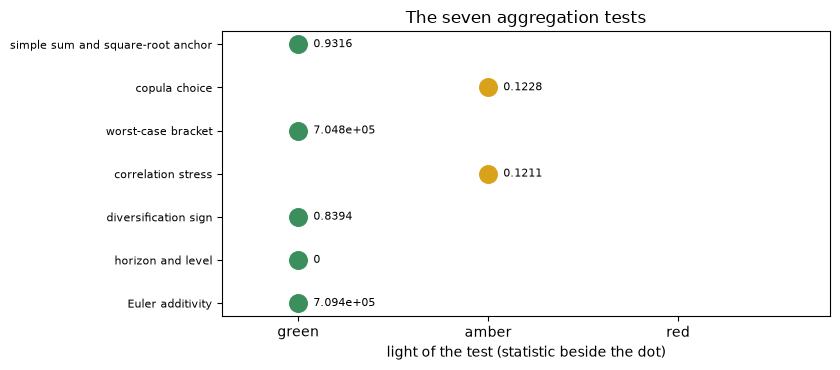

In [4]:
# Run the seven aggregation tests and draw each at the light it gets
results = {
    "aggregation.simple_sum_and_variance_covariance": agg_tests.simple_sum_and_variance_covariance(ec, R, gaussian),
    "aggregation.copula_choice_sensitivity": agg_tests.copula_choice_sensitivity(gaussian, t_caps),
    "aggregation.worst_case_bracket": agg_tests.worst_case_bracket(lower, between, worst),
    "aggregation.correlation_stress": agg_tests.correlation_stress(gaussian, stressed[("gaussian-copula", None)]),
    "aggregation.diversification_sign": agg_tests.diversification_sign(diversified),
    "aggregation.horizon_confidence_consistency": agg_tests.horizon_confidence_consistency([1] * 4, [0.999] * 4),
    "portfolio.euler_additivity": port_tests.euler_additivity(contributions, es_total, 1e-6),
}
order = ["green", "amber", "red"]
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for k, (test_id, result) in enumerate(results.items()):
    level = order.index(result.light.value)
    ax.scatter([level], [-k], s=160, color=COLOUR[result.light.value])
    ax.text(level + 0.08, -k, f"{result.statistic:.4g}", va="center", fontsize=8)
    print(f"{TEST[test_id]:48s} {LIGHT[result.light.value]:6s} {result.statistic:14.4f}")
ax.set_yticks([-k for k in range(len(results))])
ax.set_yticklabels([TEST[t] for t in results], fontsize=8)
ax.set_xticks(range(3))
ax.set_xticklabels([LIGHT[c] for c in order])
ax.set_xlim(-0.4, 2.8)
ax.set_xlabel("light of the test (statistic beside the dot)")
ax.set_title("The seven aggregation tests")
spread = results["aggregation.copula_choice_sensitivity"].statistic
stress = results["aggregation.correlation_stress"].statistic
print("copula spread and correlation stress, percent", round(spread * 100, 1), round(stress * 100, 1))
fig.tight_layout()
plt.show()

Five tests are green and two are amber, and the two amber ones say something. The copula choice moves the capital by up to
12.3 percent, the t copula with four degrees of freedom against the Gaussian, above the 5 percent gate: the answer depends on
a modelling choice that no data in the case can settle. The market-credit stress to 0.8 raises the Gaussian row by 12.1
percent, above its 10 percent gate: the answer depends on a correlation that is a convention. Neither is a failure of the
model, each is a sensitivity the reader must see, which is why the band is shown whole. The aggregate is 93.2 percent of the
square-root anchor and the worst-case bracket holds.

**The Monte Carlo agreement test.** In the one case where the square-root formula is exact, normal marginals with a Gaussian copula, a simulation must agree with it. `elliptical_mc_agreement(mc_capital, mc_se, vc_capital, z)` checks that the simulated capital is within $z = 3$ standard errors of the formula: it is the test of the simulator itself.

The next cell runs that simulation as the pipeline does, with normal marginals that have the committed capitals, one million
draws and seed 49 (the seed of the case, 42, plus 7), and draws the simulated capital with three standard errors around it
against the formula. It also runs the horizon-and-level check on a planted mismatch, one marginal at a ten-day horizon.

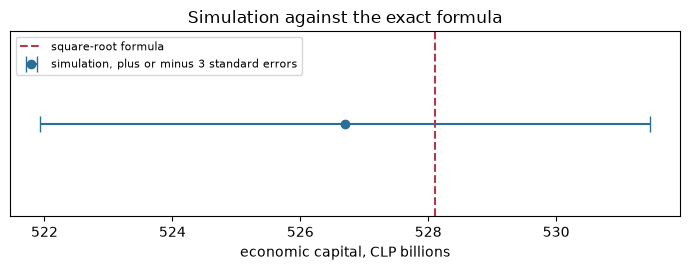

simulated capital and standard error 526698.8 1587.1
statistic, in standard errors, and light -0.8868 green
planted ten-day marginal red ['irrbb']


In [5]:
# The Monte Carlo agreement test with normal marginals and a Gaussian copula, and the horizon check on a mismatch
LEVEL = 0.999
z_level = stats.norm.ppf(LEVEL)
normal_ppfs = [partial(stats.norm.ppf, scale=capital / z_level) for capital in ec]
simulation = cop.copula_aggregate(normal_ppfs, R, "gaussian", None, 0.0, LEVEL, 1_000_000, 49, 100_000)
vc_total = simple.variance_covariance(ec, R)
agreement = agg_tests.elliptical_mc_agreement(simulation.ec, simulation.var_se, vc_total)
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.errorbar([simulation.ec / 1e3], [0], xerr=[3 * simulation.var_se / 1e3], fmt="o", color="#2a6f97", capsize=6,
            label="simulation, plus or minus 3 standard errors")
ax.axvline(vc_total / 1e3, color="#b23a48", linestyle="--", label="square-root formula")
ax.set_yticks([])
ax.set_xlabel("economic capital, CLP billions")
ax.set_title("Simulation against the exact formula")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()
print("simulated capital and standard error", round(simulation.ec, 1), round(simulation.var_se, 1))
print("statistic, in standard errors, and light", round(agreement.statistic, 4), LIGHT[agreement.light.value])
planted = agg_tests.horizon_confidence_consistency([1.0, 1.0, 10 / 250, 1.0], [0.999] * 4)
offending = [agg["marginals"][i]["risk"] for i in planted.extras["offending_indices"]]
print("planted ten-day marginal", LIGHT[planted.light.value], offending)

The simulated capital is 526,699 million with a standard error of 1,587, which is 0.89 standard errors below the square-root
anchor of 528,106 million, well inside the gate of three. This is the test of the simulator itself, in the one case where
the formula is exact, and the figure shows the formula sitting inside the error bar. The planted ten-day marginal turns the
horizon and level check red and names the third marginal, interest rate risk. A test that never fails has not been shown to
work, which is why a mismatch is planted here.

### Step 2: the satellite back-cast

A satellite is validated **out of time**: fit it on data that ends before an episode, run it through the episode on the **realised** macro variables, and compare predicted and realised loss rates (dossier 05, H.7). The case fits on 1985 to 2019 and back-casts 2020 Q1 to 2025 Q4, which holds the pandemic shock. `satellite_backcast(predicted, realised, quarters, fit_end, peak_amber, peak_red, timing_quarters)` compares the peaks:

- **statistic** the RMSE of predicted against realised; **metric** the timing error in quarters (predicted peak quarter less realised peak quarter);
- light **green** when the predicted peak is within 35 percent of the realised peak in size and within 2 quarters in timing, **amber** within 60 percent, **red** otherwise;
- the light **`error`** when the fit window is not strictly before the episode: a back-cast on data it was fitted on is leakage, and the test refuses to run.

The next cell recomputes the test for the five loan types from the committed predicted and realised quarters, draws predicted
against realised rates and prints the peak ratio, the timing and the RMSE. It then plants a leak, a fit that ends in 2020 Q2.

commercial and industrial  peak ratio    4.55 timing    0 RMSE 0.0055 red
commercial real estate     peak ratio   13.14 timing  -14 RMSE 0.0079 red
residential mortgages      peak ratio  252.13 timing  -12 RMSE 0.0068 red
credit cards               peak ratio    4.30 timing  -17 RMSE 0.0371 red
other consumer             peak ratio    2.09 timing  -21 RMSE 0.0051 red


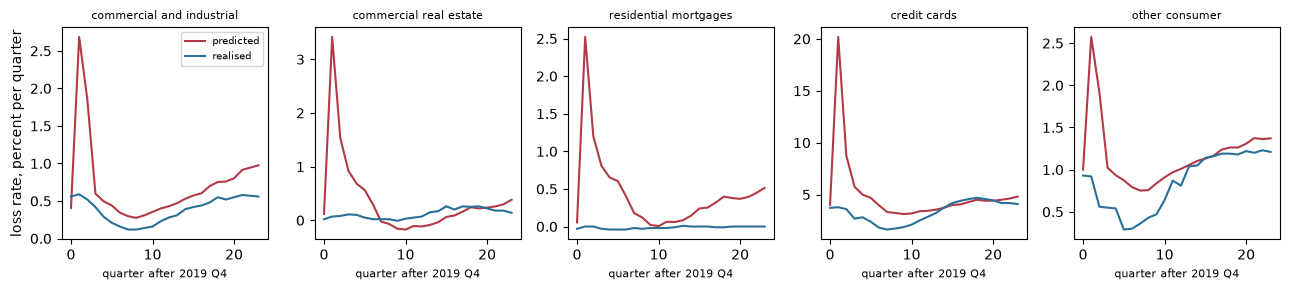

fit window ending 2020-06-30 error


In [6]:
# The back-cast test of each loan type from the committed quarters, and a fit window that leaks
LOAN = {"commercial-industrial": "commercial and industrial",
        "commercial-real-estate": "commercial real estate",
        "residential": "residential mortgages", "credit-cards": "credit cards",
        "other-consumer": "other consumer"}
backcast = {b["fed_loan_type"]: b for b in baseline["backcast"]["per_loan_type"]}
fig, axes = plt.subplots(1, 5, figsize=(13, 3), sharex=True)
for ax, (loan_type, block) in zip(axes, backcast.items()):
    predicted = [q["predicted"] for q in block["quarters"]]
    realised = [q["realised"] for q in block["quarters"]]
    ends = [q["quarter_end"] for q in block["quarters"]]
    result = stress_tests.satellite_backcast(predicted, realised, ends, block["fit_window"]["end"])
    ax.plot(np.array(predicted) * 100, color="#b23a48", label="predicted")
    ax.plot(np.array(realised) * 100, color="#2a6f97", label="realised")
    ax.set_title(LOAN[loan_type], fontsize=8)
    ax.set_xlabel("quarter after 2019 Q4", fontsize=8)
    print(f"{LOAN[loan_type]:26s} peak ratio {result.extras['peak_ratio']:7.2f} timing {result.metric:4.0f}"
          f" RMSE {result.statistic:.4f} {LIGHT[result.light.value]}")
axes[0].set_ylabel("loss rate, percent per quarter")
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()
block = backcast["credit-cards"]
quarters = [q["quarter_end"] for q in block["quarters"]]
leak = stress_tests.satellite_backcast([q["predicted"] for q in block["quarters"]],
                                       [q["realised"] for q in block["quarters"]], quarters, "2020-06-30")
print("fit window ending 2020-06-30", LIGHT[leak.light.value])

All five satellites are red. Every one predicts its largest loss rate in 2020 Q2, the quarter of the shock, from 2.09 times
the realised peak for other consumer loans to 252 times for residential mortgages. Only commercial and industrial loans
actually peaked then, and the other four realised their peaks 12 to 21 quarters later: the satellites react strongly to the
realised macro variables of 2020, and the realised charge-offs did not follow. A validator reads this as a finding about the
stressed numbers of the case, because the credit loss of a severe scenario rests on satellites that would have overstated
the one downturn that fell inside the back-cast. The fit window that ends in 2020 Q2 is refused as an error.

### Step 3: signs, severity, the static rules and bottom-up against top-down

**Signs.** `sensitivity_monotonicity(estimates, expected_signs)` counts the coefficients with the wrong sign against the sign declared **before** the fit (growth lowers the loss rate: negative; unemployment raises it: positive; the autoregressive term: positive), so the projected loss is monotone in the severity of the path. It is red when any coefficient is wrong.

**Severity.** `scenario_severity(path_peak, history_peak, is_stress, minimum)` compares the peak deviation of a scenario variable with the same deviation in the global financial crisis (2008 Q1 to 2009 Q4): the ratio must be at least 0.75, green if so and **amber** below (no red: a mild stress is a finding about the scenario, not a failure); the baseline is not a stress path and is `not_evaluated`.

**Static rules.** `static_balance_sheet_rules` was run in notebook 05.

**Bottom-up against top-down.** `bottom_up_vs_top_down(bottom_up, top_down, amber, red)` compares the bank's stressed loss with a **challenger** model's: green within 25 percent, amber within 50, red beyond. The case bakes no top-down challenger, so the rule is shown on the one pair of totals the documents give that differ only by scenario, the three-year loss of the Federal Reserve's and the EBA's adverse scenarios, as a demonstration of the rule and not as a challenger comparison.

The next cell runs the sign test on the 30 coefficients and draws each estimate times its declared sign, so that a negative
bar is a coefficient with the wrong sign, then runs the severity test on every scenario variable and draws the ratio to the
crisis against the 0.75 gate, and applies the bottom-up rule to the two adverse losses.

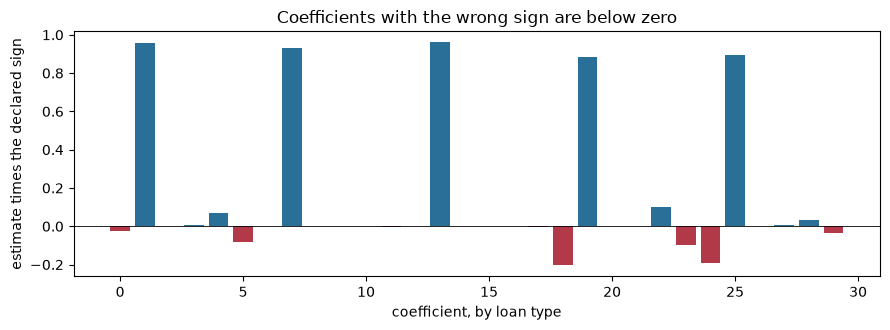

coefficients tested, wrong sign, light
30 6 red
  commercial and industrial: real_gdp_growth_lag0      +0.00069
  commercial real estate: real_gdp_growth_lag1         +0.00005
  residential mortgages: real_gdp_growth_lag0          +0.00005
  residential mortgages: real_gdp_growth_lag1          +0.00006
  credit cards: real_gdp_growth_lag0                   +0.00038
  credit cards: real_gdp_growth_lag1                   +0.00057


In [7]:
# The sign test on the 30 satellite coefficients: each estimate times the sign declared before the fit
estimates, signs, labels = [], [], []
for model in models["satellites"]:
    for coefficient in model["coefficients"]:
        estimates.append(coefficient["estimate"])
        signs.append(coefficient["expected_sign"])
        labels.append(f'{LOAN[model["fed_loan_type"]]}: {coefficient["name"]}')
sign_test = stress_tests.sensitivity_monotonicity(estimates, signs)
direction = np.array([-1.0 if s == "negative" else 1.0 for s in signs])
signed = np.array(estimates) * direction
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(range(len(signed)), signed, color=["#b23a48" if v < 0 else "#2a6f97" for v in signed])
ax.axhline(0, color="black", linewidth=0.6)
ax.set_xlabel("coefficient, by loan type")
ax.set_ylabel("estimate times the declared sign")
ax.set_title("Coefficients with the wrong sign are below zero")
fig.tight_layout()
plt.show()
print("coefficients tested, wrong sign, light")
print(sign_test.n, int(sign_test.statistic), LIGHT[sign_test.light.value])
for index in sign_test.extras["offending_indices"]:
    print(f"  {labels[index]:52s} {estimates[index]:+.5f}")

Six of the 30 coefficients have the wrong sign, and all six are GDP-growth coefficients: commercial and industrial (lag 0),
commercial real estate (lag 1), residential (lags 0 and 1) and credit cards (lags 0 and 1) come out slightly positive where
a negative sign was declared before the fit. They are tiny, between 0.00005 and 0.0007, next to the unemployment
coefficients, which carry the projection, so the practical effect is small, but the test is red by its rule. The rule exists
so that a satellite's projected loss is monotone in the severity of the path, and six small violations are enough to say it is
not guaranteed.

Fed baseline             unemployment_rate   0.000 not evaluated
Fed baseline             real_gdp_growth     0.000 not evaluated
Fed baseline             prime_rate          0.000 not evaluated
EBA adverse              real_gdp_growth     0.711 amber
EBA adverse              unemployment_rate   1.170 green
EBA adverse              treasury_10y        1.128 green
Fed severely adverse     unemployment_rate   1.078 green
Fed severely adverse     real_gdp_growth     0.582 amber
Fed severely adverse     prime_rate          0.929 green
NGFS                     unemployment_rate   0.112 amber
NGFS                     prime_rate          0.144 amber
NGFS                     treasury_10y        0.112 amber
NGFS                     real_gdp_growth     0.036 amber


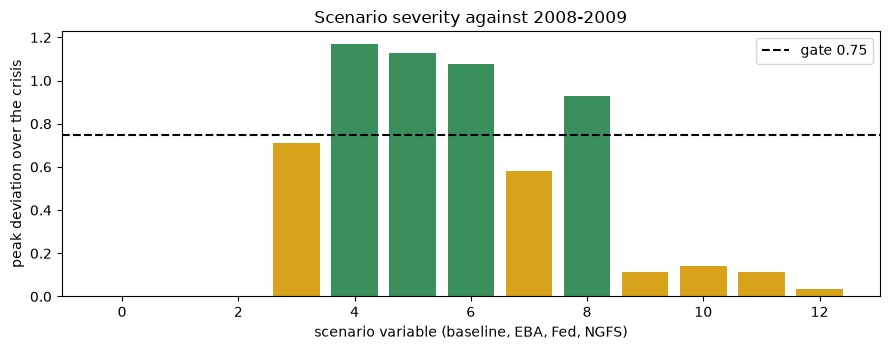

EBA loss over Fed loss, less one 0.0727 green


In [8]:
# The severity of every scenario variable against the global financial crisis, and the bottom-up rule on two losses
SCENARIO = {"baseline": "Fed baseline", "eba-2025-adverse": "EBA adverse",
            "fed-2026-severely-adverse": "Fed severely adverse", "ngfs-delayed-transition": "NGFS"}
fig, ax = plt.subplots(figsize=(9, 3.6))
position = 0
for name, document in {"baseline": baseline_doc, **variants}.items():
    for severity in document["outputs"]["severity"]["rows"]:
        args = (severity["path_peak_deviation"], severity["history_peak_deviation"], severity["is_stress"])
        result = stress_tests.scenario_severity(*args)
        ratio = 0.0 if result.statistic != result.statistic else result.statistic
        ax.bar(position, ratio, color=COLOUR[result.light.value])
        position += 1
        print(f"{SCENARIO[name]:24s} {severity['maps_to_regressor']:18s} {ratio:6.3f} {LIGHT[result.light.value]}")
ax.axhline(0.75, color="black", linestyle="--", label="gate 0.75")
ax.set_xlabel("scenario variable (baseline, EBA, Fed, NGFS)")
ax.set_ylabel("peak deviation over the crisis")
ax.set_title("Scenario severity against 2008-2009")
ax.legend()
fig.tight_layout()
plt.show()
totals = {name: sum(r["total"] for r in d["outputs"]["losses"]["scenario_losses"]) for name, d in variants.items()}
demo = stress_tests.bottom_up_vs_top_down(totals["eba-2025-adverse"], totals["fed-2026-severely-adverse"])
print("EBA loss over Fed loss, less one", round(demo.statistic, 4), LIGHT[demo.light.value])

Severity is mixed. The Federal Reserve severely adverse scenario passes on unemployment (1.078 times the crisis) and the
prime rate (0.929) and is amber on GDP growth, at 0.582. The EBA adverse scenario is amber on GDP growth (0.711) and green
elsewhere. Every NGFS variable is amber, between 0.04 and 0.14, because the delayed-transition shock is a climate-policy shock
far milder in macro terms than the crisis, and the baseline bars are zero because the baseline is not a stress path and is not
evaluated. The bottom-up rule is shown and not run on a challenger: the EBA adverse three-year loss is 7.3 percent above the
Federal Reserve severe one, green against the 25 and 50 percent gates.

## Results

The next cell tallies every committed test row of the case by test and light, the 17 rows of the baseline document and the two
aggregation tests that only the second document carries, so that the whole battery is visible at once.

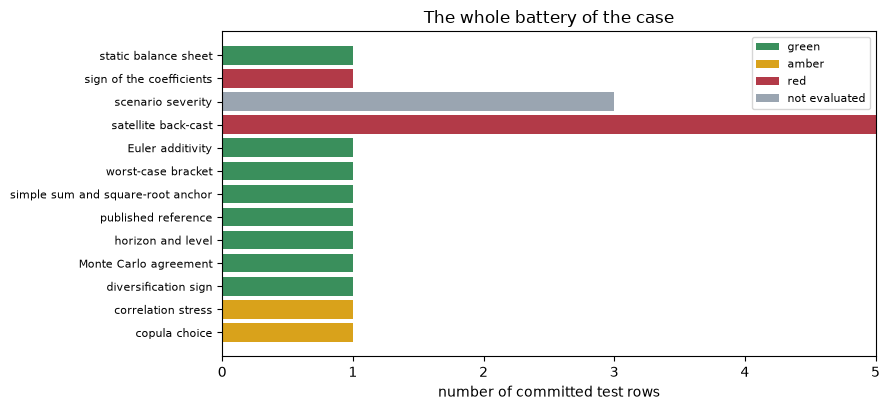

committed rows 19 {'green': 8, 'amber': 2, 'red': 6, 'not_evaluated': 3}


In [9]:
# Tally the committed test rows of C18 by test and light across the baseline and the second document
extra = ("aggregation.elliptical_mc_agreement", "aggregation.rosenberg_schuermann_reference")
rows = baseline_doc["tests"] + [t for t in second["tests"] if t["test_id"] in extra]
ids = sorted({t["test_id"] for t in rows})
fig, ax = plt.subplots(figsize=(9, 4.2))
left = np.zeros(len(ids))
for light in ("green", "amber", "red", "not_evaluated"):
    counts = np.array([sum(1 for t in rows if t["test_id"] == i and t["light"] == light) for i in ids])
    ax.barh(range(len(ids)), counts, left=left, color=COLOUR[light], label=LIGHT[light])
    left += counts
ax.set_yticks(range(len(ids)))
ax.set_yticklabels([TEST.get(i, i) for i in ids], fontsize=8)
ax.set_xlabel("number of committed test rows")
ax.set_title("The whole battery of the case")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print("committed rows", len(rows), dict(Counter(t["light"] for t in rows)))

The red bars are all in the stress layer: the back-cast of the five satellites and the sign test, while the aggregation
tests are green or amber. Of 19 committed rows, 8 are green, 2 are amber, 6 are red and 3 are not evaluated, and the reading
is the same as that of the recomputed tests above. The aggregation can be defended with its sensitivities shown; the stressed
credit loss cannot be defended more than as a reading of its satellites, which fail their own validation.

**Answer:** the aggregation holds up and the stress satellites do not. The seven aggregation tests give five green lights and two
amber ones, the copula choice (a 12.3 percent spread against a 5 percent gate) and the correlation stress (12.1 percent against
10), both sensitivities that the band exists to show, and the Monte Carlo agreement test is green at 0.89 standard errors from
the exact formula. The stress layer fails: all five satellites are red in the back-cast, with predicted peaks from 2.09 to
252.13 times the realised ones, and six of 30 coefficients have the wrong sign. Across the 19 committed test rows the tally is 8
green, 2 amber, 6 red and 3 not evaluated, so the stressed credit loss of notebook 05 rests on satellites that the engine's own
battery marks red.

What this notebook does not show: the gates are Contraste's internal ones, so a light is a reading of that policy and not a
regulatory verdict; the case has no challenger model, so bottom-up against top-down was demonstrated and not performed; and the
lights say the satellites are weak, not what a better model would give.

## Summary

- The engine has one test for each check of dossier 05: seven for the aggregation (plus the Monte Carlo agreement and the published reference) and six for the stress, each with a stated rule and gates that are Contraste's, not the regulator's.
- Recomputed from the committed numbers, every aggregation test and the back-cast, sign and severity tests give the committed light and statistic; the Monte Carlo agreement test is green on a fresh simulation.
- The two amber aggregation lights are sensitivities (the copula choice and the correlation stress) that the band exists to show; the red lights are about the **satellites**: all five fail their back-cast and six coefficients have the wrong sign.
- The tests refuse what they should: a mismatched horizon is red, a fit window that leaks into the episode is `error`, and a scenario milder than the global financial crisis is amber.
- The consequence is not that the case is wrong, but that its stressed credit loss rests on satellites that its own validation battery marks red.

**What to try next.** Replace the amber and red gates of one test with your own and see which lights change; then continue with notebook 08, the state of the art, which sets the case's aggregation and satellites next to the supervisory models and the model-risk measures.

## References

- Rosenberg, J. V. and Schuermann, T. (2006), A general approach to integrated risk management with skewed, fat-tailed risks, Journal of Financial Economics 79(3). https://doi.org/10.1016/j.jfineco.2005.03.001
- Embrechts, P., Puccetti, G. and Rueschendorf, L. (2013), Model uncertainty and VaR aggregation, Journal of Banking and Finance 37(8). https://doi.org/10.1016/j.jbankfin.2013.03.014
- EBA (2025), 2025 EU-wide stress test, Methodological Note of 2025-01-20: the static balance sheet (paragraphs 24, 33, 34 and 90 to 92). https://www.eba.europa.eu/sites/default/files/2025-01/0246e2f3-fa57-47d1-99f2-7a5b80cae509/2025%20EU-wide%20stress%20test%20-%20Methodological%20Note.pdf
- Dossier 05 of the persisted Contraste research (G.5, validation tests for an economic capital model, and H.7, what validators test in a stress model), as summarised in the SDD's research basis.
- This repository: `docs/contracts/engine/aggregation-api.md` and `docs/contracts/engine/stress-api.md` (the validation tests and their rules) and `docs/design/features/c18/validation.md`.